In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [7]:
df= pd.read_csv("../Student_Performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0


c:\Users\sibi\Desktop\My project\studentperformace\mlmodel


In [8]:
df.isnull().sum()

Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours                         0
Sample Question Papers Practiced    0
Performance Index                   0
dtype: int64

In [10]:
for i in ["Hours Studied","Sleep Hours","Sample Question Papers Practiced"]:
    print(i,":",df[i].unique())
    print("="*60)

Hours Studied : [7 4 8 5 3 6 2 1 9]
Sleep Hours : [9 4 7 5 8 6]
Sample Question Papers Practiced : [1 2 5 6 0 8 3 4 9 7]


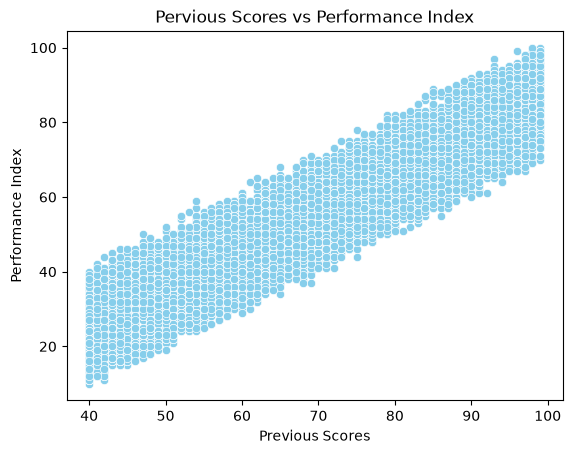

In [ ]:
sns.scatterplot(x="Previous Scores",y="Performance Index",color="skyblue",data=df)
plt.title("Pervious Scores vs Performance Index")
plt.show()
#When X Increase here the Y also Increase so it is a Positive corelation

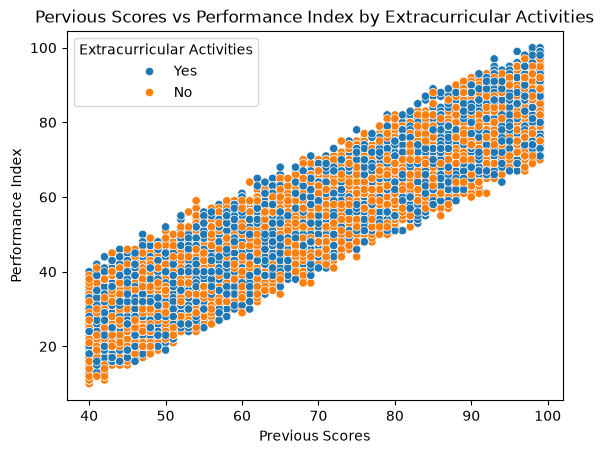

In [13]:
sns.scatterplot(x="Previous Scores",y="Performance Index",hue="Extracurricular Activities",color="skyblue",data=df)
plt.title("Pervious Scores vs Performance Index by Extracurricular Activities")
plt.show()

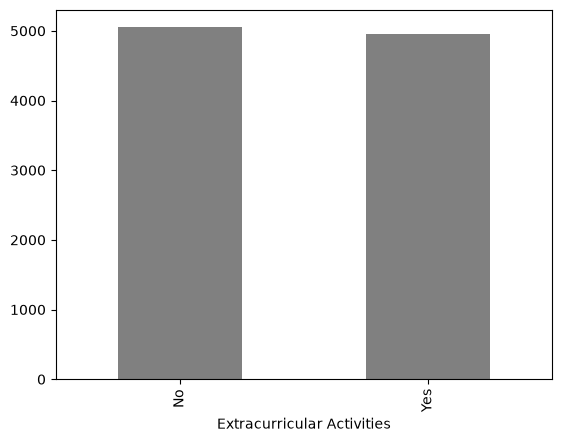

Extracurricular Activities
No     5052
Yes    4948
Name: count, dtype: int64


In [14]:
df["Extracurricular Activities"].value_counts().plot(kind="bar",color="gray")
plt.show()
print(df["Extracurricular Activities"].value_counts())

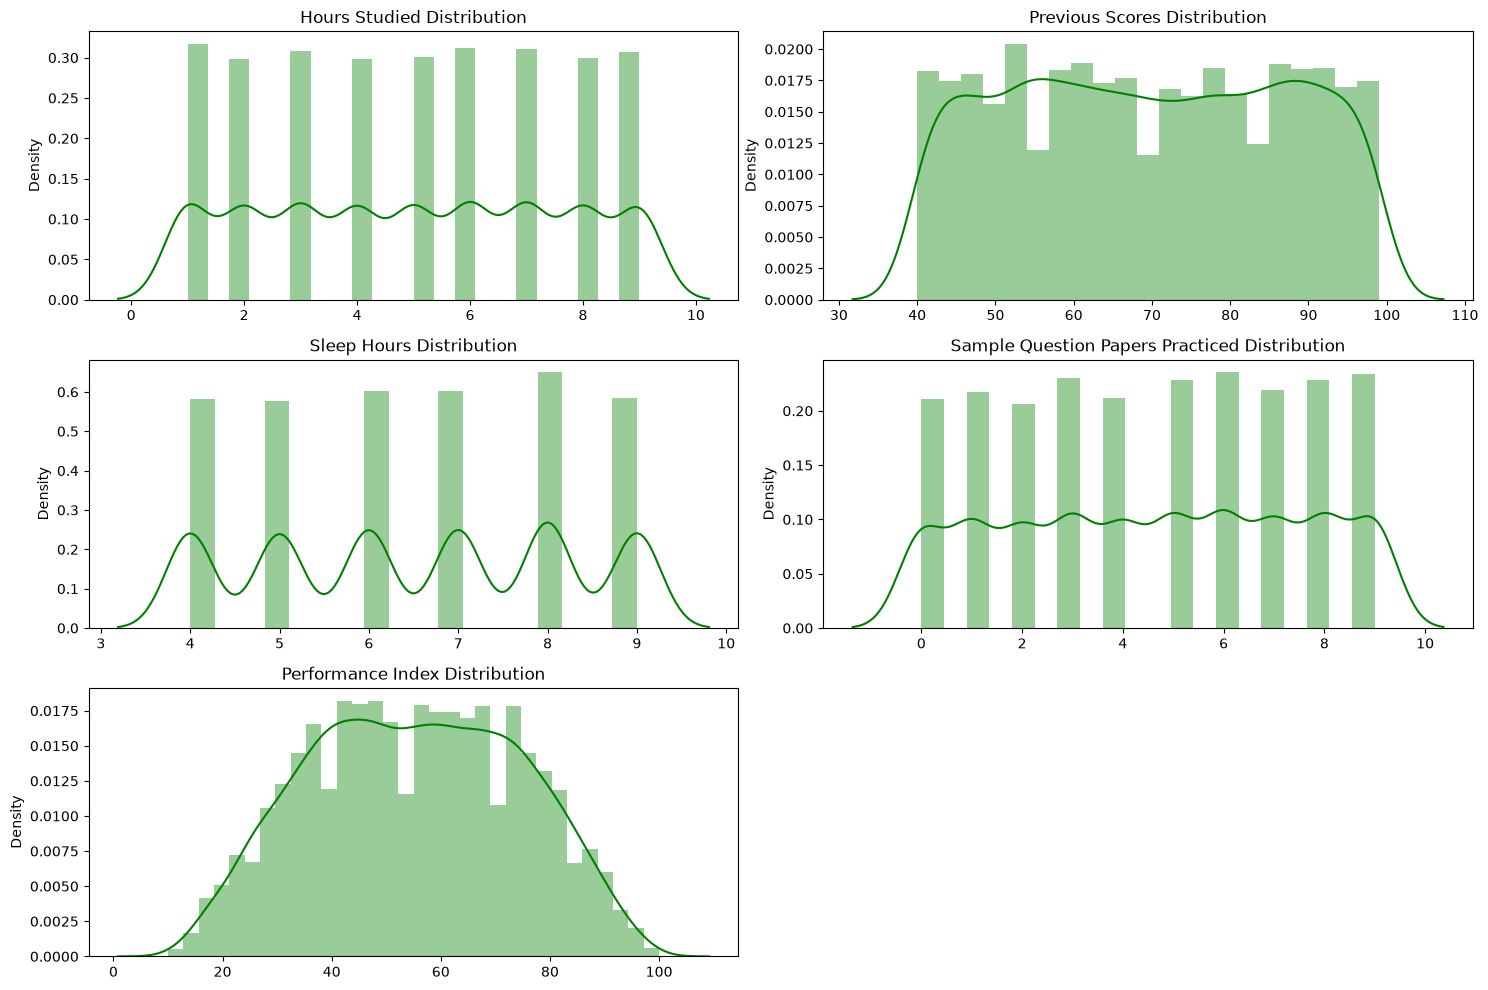

In [ ]:
plt.figure(figsize=(15,10))
for i,col in enumerate(["Hours Studied","Previous Scores","Sleep Hours","Sample Question Papers Practiced","Performance Index"]):
    plt.subplot(3,2,i+1)
    sns.distplot(df[col],color="green")
    plt.title(f"{col} Distribution")
    plt.xlabel("")
plt.tight_layout()
plt.show()
#Probability Distribution

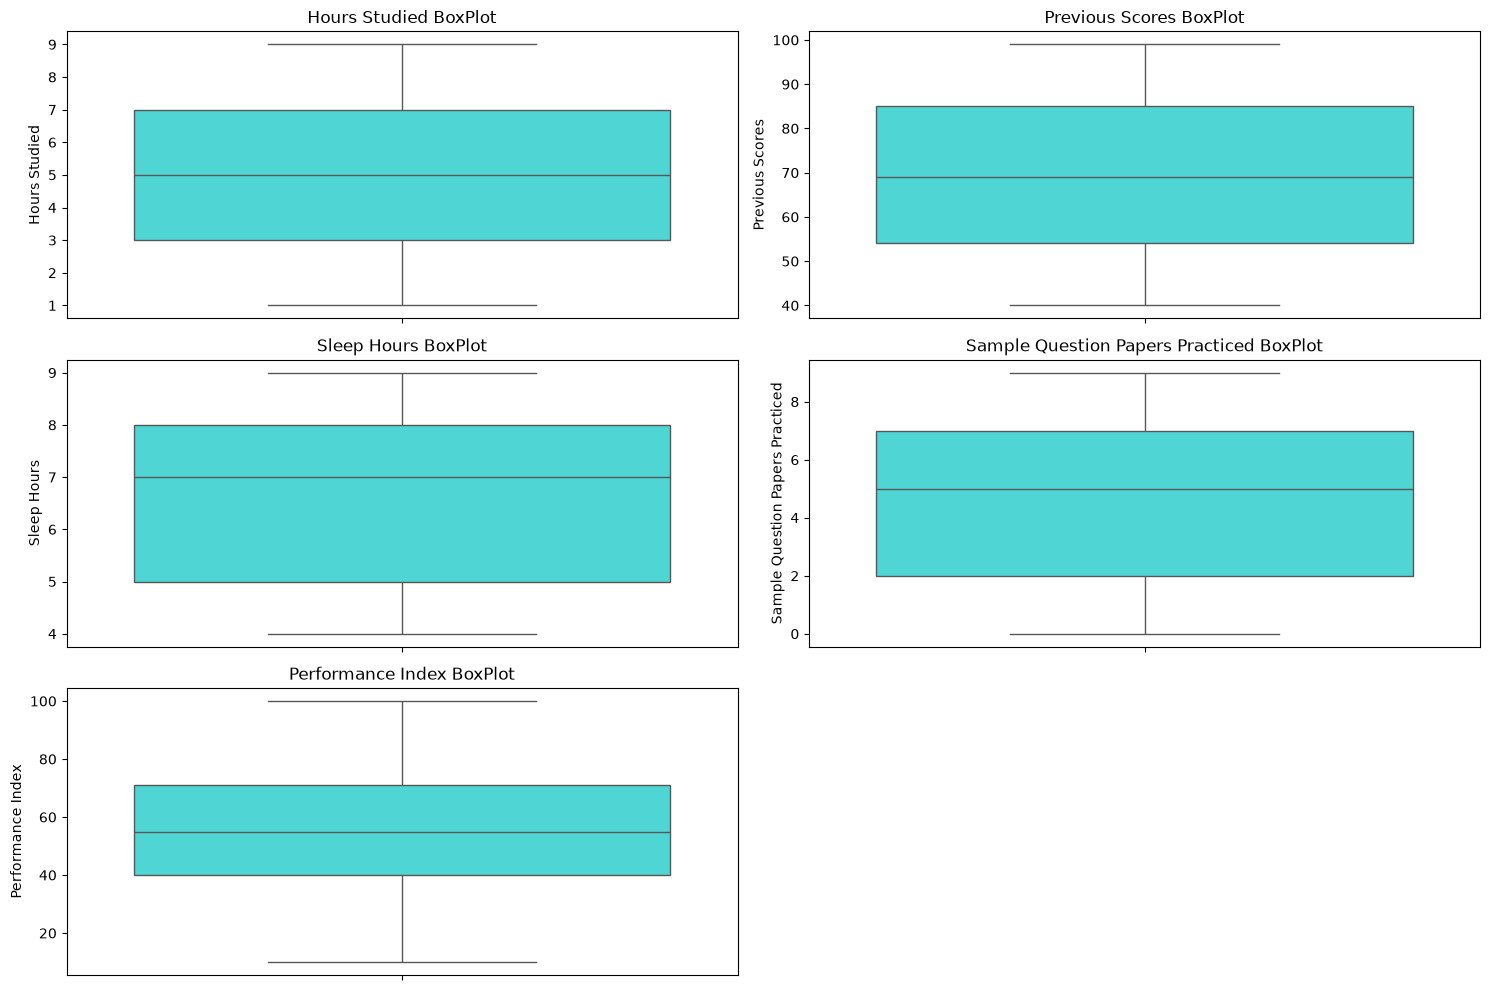

In [ ]:
#Finding outlayer 
plt.figure(figsize=(15,10))
for i,col in enumerate(["Hours Studied","Previous Scores","Sleep Hours","Sample Question Papers Practiced","Performance Index"]):
    plt.subplot(3,2,i+1)
    sns.boxplot(df[col],color="#39EBE9")
    plt.title(f"{col} BoxPlot")
    plt.xlabel("")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import train_test_split

X = df.drop("Performance Index",axis=1)
y = df["Performance Index"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,random_state=42)
print((f"X train shape : {X_train.shape}"))
print(f"X test shape : {X_test.shape}")

X train shape : (7500, 5)
X test shape : (2500, 5)


In [ ]:
#Convert the yes to 1 and No to 0 in the Extracurricular Activities column
X_train["Extracurricular Activities"] = X_train["Extracurricular Activities"].map({"Yes":1,"No":0})
X_test["Extracurricular Activities"] = X_test["Extracurricular Activities"].map({"Yes":1,"No":0})
print(X_train["Extracurricular Activities"].unique())
print(X_test["Extracurricular Activities"].unique())

[0 1]
[0 1]


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
cols_for_scaler = ["Hours Studied","Previous Scores","Sleep Hours","Sample Question Papers Practiced"]
X_train[cols_for_scaler] = scaler.fit_transform(X_train[cols_for_scaler])
X_test[cols_for_scaler] = scaler.transform(X_test[cols_for_scaler])

In [19]:
X_train.head(3)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced
4901,5,49,0,5,5
4375,7,88,1,4,9
6698,3,94,1,7,1


In [29]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

In [21]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [22]:
# This function is used to predict the error Value
def calculate_model_metrics(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mean_squared_error(true, predicted))
    r2_square = r2_score(true, predicted)
    return mae, rmse, r2_square

In [31]:
models = {
    "Linear Regression" : LinearRegression(),
    "Lasso": Lasso(),
    "Ridge" : Ridge(),
    "Elasticnet": ElasticNet(),
    "K-Neighbors Regressor"  : KNeighborsRegressor(),
    "Decision Tree" : DecisionTreeRegressor(),
    "Random Forest Regressor" : RandomForestRegressor(),
    "Support Vector Regressir" :SVR(kernel="linear")
}

In [32]:
for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_mae, model_train_rmse, model_train_r2 = calculate_model_metrics(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = calculate_model_metrics(y_test, y_test_pred)

    print(list(models.values())[i]) 
    
    print("RMSE :", model_test_rmse)
    print("Mean Absolute Error :", model_test_mae)
    print("R2 Score :", model_test_r2)

    print("-----------------------------")

LinearRegression()
RMSE : 2.0081195719924434
Mean Absolute Error : 1.5975792091646104
R2 Score : 0.9890550757439104
-----------------------------
Lasso()
RMSE : 2.1954630374044095
Mean Absolute Error : 1.735894295901938
R2 Score : 0.9869176464437092
-----------------------------
Ridge()
RMSE : 2.008123820250986
Mean Absolute Error : 1.5975800205432165
R2 Score : 0.9890550294349975
-----------------------------
ElasticNet()
RMSE : 2.1911455426928965
Mean Absolute Error : 1.7293004357445956
R2 Score : 0.9869690501366244
-----------------------------
KNeighborsRegressor()
RMSE : 2.4317006394702454
Mean Absolute Error : 1.9412
R2 Score : 0.9839507833228293
-----------------------------
DecisionTreeRegressor()
RMSE : 2.9678911330737483
Mean Absolute Error : 2.3454666666666664
R2 Score : 0.9760927537438592
-----------------------------
RandomForestRegressor()
RMSE : 2.2712768458400565
Mean Absolute Error : 1.8204178920634921
R2 Score : 0.9859985256352607
-----------------------------
SVR(ker

In [33]:
for name, model in models.items():
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_mae, model_train_rmse, model_train_r2 = calculate_model_metrics(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = calculate_model_metrics(y_test, y_test_pred)

    print(f"========== Model: {name} ==========")
    print(f"Train R2: {model_train_r2:.4f}  |  Test R2: {model_test_r2:.4f}")
    print(f"Train RMSE: {model_train_rmse:.4f}  |  Test RMSE: {model_test_rmse:.4f}")
    print("--------------------------------------------------")

========== Model: Linear Regression ==========
Train R2: 0.9886  |  Test R2: 0.9891
Train RMSE: 2.0479  |  Test RMSE: 2.0081
--------------------------------------------------
========== Model: Lasso ==========
Train R2: 0.9867  |  Test R2: 0.9869
Train RMSE: 2.2118  |  Test RMSE: 2.1955
--------------------------------------------------
========== Model: Ridge ==========
Train R2: 0.9886  |  Test R2: 0.9891
Train RMSE: 2.0479  |  Test RMSE: 2.0081
--------------------------------------------------
========== Model: Elasticnet ==========
Train R2: 0.9866  |  Test R2: 0.9870
Train RMSE: 2.2201  |  Test RMSE: 2.1911
--------------------------------------------------
========== Model: K-Neighbors Regressor ==========
Train R2: 0.9888  |  Test R2: 0.9840
Train RMSE: 2.0324  |  Test RMSE: 2.4317
--------------------------------------------------
========== Model: Decision Tree ==========
Train R2: 0.9993  |  Test R2: 0.9760
Train RMSE: 0.4996  |  Test RMSE: 2.9719
--------------------------

MAE: What is the average absolute difference between actual and predicted values?
RMSE: How large are the prediction errors, with larger errors penalized more heavily?
R² Score: How well does your model explain the variation in the actual values compared with predicting their mean?

In [34]:
from sklearn.metrics import r2_score
import pandas as pd

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    results.append({
        "Model": name,
        "Train R2": train_r2,
        "Test R2": test_r2,
        "Difference": train_r2 - test_r2
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("Test R2", ascending=False)

results_df

,Model,Train R2,Test R2,Difference
0,Linear Regression,0.988640,0.989055,-0.000416
2,Ridge,0.988640,0.989055,-0.000415
7,Support Vector Regressir,0.988636,0.989042,-0.000406
3,Elasticnet,0.986648,0.986969,-0.000321
1,Lasso,0.986748,0.986918,-0.000169
6,Random Forest Regressor,0.997463,0.986042,0.011420
4,K-Neighbors Regressor,0.988810,0.983951,0.004859
5,Decision Tree,0.999324,0.976092,0.023232


In [35]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

for depth in [2, 3, 5, 10, 15, None]:

    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_r2 = r2_score(y_train, model.predict(X_train))
    test_r2 = r2_score(y_test, model.predict(X_test))

    print(
        f"Depth: {depth} | "
        f"Train R2: {train_r2:.4f} | "
        f"Test R2: {test_r2:.4f}"
    )

Depth: 2 | Train R2: 0.7897 | Test R2: 0.7835
Depth: 3 | Train R2: 0.8979 | Test R2: 0.8924
Depth: 5 | Train R2: 0.9650 | Test R2: 0.9622
Depth: 10 | Train R2: 0.9916 | Test R2: 0.9830
Depth: 15 | Train R2: 0.9991 | Test R2: 0.9763
Depth: None | Train R2: 0.9993 | Test R2: 0.9760


Max depth	         Test R²	           Interpretation
2	                 0.7835	               Too simple, likely underfitting
3	                 0.8924	               Better, but still less effective
5	                 0.9622	               Good performance
10	                 0.9830	               Best test score in this experiment
15	                 0.9763	               Signs of overfitting
None	             0.9760                Signs of overfitting




In [36]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

for leaf in [1, 2, 5, 10, 20]:

    model = DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=leaf,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_r2 = r2_score(y_train, model.predict(X_train))
    test_r2 = r2_score(y_test, model.predict(X_test))

    print(
        f"Leaf: {leaf} | "
        f"Train R2: {train_r2:.4f} | "
        f"Test R2: {test_r2:.4f}"
    )

Leaf: 1 | Train R2: 0.9916 | Test R2: 0.9830
Leaf: 2 | Train R2: 0.9913 | Test R2: 0.9834
Leaf: 5 | Train R2: 0.9904 | Test R2: 0.9847
Leaf: 10 | Train R2: 0.9888 | Test R2: 0.9849
Leaf: 20 | Train R2: 0.9862 | Test R2: 0.9838


In [37]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

for split in [2, 5, 10, 20, 50]:

    model = DecisionTreeRegressor(
        max_depth=10,
        min_samples_leaf=10,
        min_samples_split=split,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_r2 = r2_score(y_train, model.predict(X_train))
    test_r2 = r2_score(y_test, model.predict(X_test))

    print(
        f"Min samples split: {split} | "
        f"Train R2: {train_r2:.4f} | "
        f"Test R2: {test_r2:.4f}"
    )

Min samples split: 2 | Train R2: 0.9888 | Test R2: 0.9849
Min samples split: 5 | Train R2: 0.9888 | Test R2: 0.9849
Min samples split: 10 | Train R2: 0.9888 | Test R2: 0.9849
Min samples split: 20 | Train R2: 0.9888 | Test R2: 0.9849
Min samples split: 50 | Train R2: 0.9858 | Test R2: 0.9836


In [38]:

from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

param_grid = {
    "max_depth": [5, 10, 15, None],
    "min_samples_leaf": [1, 5, 10, 20],
    "min_samples_split": [2, 10, 20, 50]
}

model = DecisionTreeRegressor(random_state=42)

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation R2:", grid_search.best_score_)


Best parameters: {'max_depth': 10, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best cross-validation R2: 0.9833897400553606


In [39]:

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

best_model = grid_search.best_estimator_

test_predictions = best_model.predict(X_test)

print("Test R2:", r2_score(y_test, test_predictions))
print("Test MAE:", mean_absolute_error(y_test, test_predictions))
print(
    "Test RMSE:",
    np.sqrt(mean_squared_error(y_test, test_predictions))
)


Test R2: 0.9849083006458111
Test MAE: 1.879522795933819
Test RMSE: 2.3580459366276934


In [40]:
import joblib

joblib.dump(best_model, "student_performance_model.pkl")

loaded_model = joblib.load("student_performance_model.pkl")

print("Model saved and loaded successfully!")

Model saved and loaded successfully!


In [41]:
# Predict one existing test sample
sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)

print("Predicted Performance Index:", prediction[0])
print("Actual Performance Index:", y_test.iloc[0])

Predicted Performance Index: 56.125
Actual Performance Index: 51.0


In [44]:

import pandas as pd

new_student = pd.DataFrame([{
    "Hours Studied": 7,
    "Previous Scores": 85,
    "Extracurricular Activities": 1,
    "Sleep Hours": 7,
    "Sample Question Papers Practiced": 4
}])

new_prediction = loaded_model.predict(new_student)

print("Predicted Performance Index:", new_prediction[0])


Predicted Performance Index: 75.93333333333334
